In [8]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected. Check your runtime settings.")

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [9]:
!pip install -q transformers datasets accelerate scikit-learn

In [10]:
import pandas as pd
import os

print("Files in current directory:")
print(os.listdir("/content"))

train = pd.read_csv("/content/train.csv")
test = pd.read_csv("/content/test.csv")
sample_submission = pd.read_csv("/content/sample_submission.csv")

print("\nTraining data:", train.shape)
print("Test data:", test.shape)
print("\nTraining columns:", train.columns.tolist())
print("\nTarget distribution:")
print(train["target"].value_counts())

Files in current directory:
['.config', 'test.csv', 'sample_submission.csv', 'train.csv', 'sample_data']

Training data: (7613, 5)
Test data: (3263, 4)

Training columns: ['id', 'keyword', 'location', 'text', 'target']

Target distribution:
target
0    4342
1    3271
Name: count, dtype: int64


In [11]:
# Step 2 — Prepare the training and validation data

from sklearn.model_selection import train_test_split

# Use original tweet text
X = train["text"].fillna("").astype(str)
y = train["target"].astype(int)

# Split into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nValidation label distribution:")
print(y_val.value_counts())

Training samples: 6090
Validation samples: 1523

Training label distribution:
target
0    3473
1    2617
Name: count, dtype: int64

Validation label distribution:
target
0    869
1    654
Name: count, dtype: int64


In [12]:
# Step 3 — Load the DistilBERT tokenizer

import torch
from transformers import AutoTokenizer

MODEL_NAME = "distilbert/distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("GPU available:", torch.cuda.is_available())
print("Tokenizer loaded:", MODEL_NAME)

example_tweet = X_train.iloc[0]

print("\nOriginal tweet:")
print(example_tweet)

print("\nTokenized tweet:")
print(tokenizer.tokenize(example_tweet))

GPU available: True
Tokenizer loaded: distilbert/distilbert-base-uncased

Original tweet:
Sassy city girl country hunk stranded in Smoky Mountain snowstorm #AoMS http://t.co/nkKcTttsD9 #ibooklove #bookboost

Tokenized tweet:
['sas', '##sy', 'city', 'girl', 'country', 'hu', '##nk', 'stranded', 'in', 'smoky', 'mountain', 'snow', '##storm', '#', 'ao', '##ms', 'http', ':', '/', '/', 't', '.', 'co', '/', 'nk', '##k', '##ct', '##tt', '##sd', '##9', '#', 'ib', '##ook', '##lov', '##e', '#', 'book', '##bo', '##ost']


In [13]:
# Step 4 — Convert tweets into DistilBERT datasets

from datasets import Dataset

# Create Hugging Face datasets
train_df = pd.DataFrame({
    "text": X_train.reset_index(drop=True),
    "labels": y_train.reset_index(drop=True)
})

val_df = pd.DataFrame({
    "text": X_val.reset_index(drop=True),
    "labels": y_val.reset_index(drop=True)
})

train_dataset = Dataset.from_pandas(train_df)
val_dataset = Dataset.from_pandas(val_df)

# Tokenization function
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        padding="max_length",
        max_length=128
    )

# Apply tokenization
train_dataset = train_dataset.map(
    tokenize_function,
    batched=True
)

val_dataset = val_dataset.map(
    tokenize_function,
    batched=True
)

# Remove raw text; retain model inputs and labels
train_dataset = train_dataset.remove_columns(["text"])
val_dataset = val_dataset.remove_columns(["text"])

# Convert to PyTorch tensors
train_dataset.set_format("torch")
val_dataset.set_format("torch")

print("Training dataset:", train_dataset)
print("Validation dataset:", val_dataset)
print("\nInput tensor shape:", train_dataset[0]["input_ids"].shape)
print("Example label:", train_dataset[0]["labels"])

Map:   0%|          | 0/6090 [00:00<?, ? examples/s]

Map:   0%|          | 0/1523 [00:00<?, ? examples/s]

Training dataset: Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 6090
})
Validation dataset: Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 1523
})

Input tensor shape: torch.Size([128])
Example label: tensor(1)


In [14]:
# Step 5 — Load the classification model

from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Model loaded successfully.")
print("Device:", device)
print("Number of classes:", model.config.num_labels)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded successfully.
Device: cuda
Number of classes: 2


In [15]:
# Step 6 — Configure the training process

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from transformers import TrainingArguments, Trainer

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "precision": precision_score(
            labels, predictions, zero_division=0
        ),
        "recall": recall_score(
            labels, predictions, zero_division=0
        ),
        "f1": f1_score(
            labels, predictions, zero_division=0
        )
    }

training_args = TrainingArguments(
    output_dir="/content/distilbert_results",
    num_train_epochs=3,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    save_total_limit=1,
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=42,
    data_seed=42
)

print("Training configuration ready.")
print("Epochs:", training_args.num_train_epochs)
print("Learning rate:", training_args.learning_rate)
print("Training batch size:", training_args.per_device_train_batch_size)

Training configuration ready.
Epochs: 3
Learning rate: 2e-05
Training batch size: 16


In [16]:
# Step 7 — Train DistilBERT

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,No log,0.377758,0.847669,0.867596,0.761468,0.811075
2,0.424519,0.379987,0.844386,0.840131,0.787462,0.812944
3,0.293280,0.422482,0.835850,0.816614,0.796636,0.806502


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1143, training_loss=0.3478480428326891, metrics={'train_runtime': 130.216, 'train_samples_per_second': 140.305, 'train_steps_per_second': 8.778, 'total_flos': 605044843361280.0, 'train_loss': 0.3478480428326891, 'epoch': 3.0})

In [17]:
# Step 8 — Evaluate the model

results = trainer.evaluate()

print("\nDistilBERT Validation Results")
print("-" * 35)

for metric, value in results.items():
    if isinstance(value, (int, float)):
        print(f"{metric}: {value:.4f}")

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.293280,0.379987,3,0.844386,0.840131,0.787462,0.812944



DistilBERT Validation Results
-----------------------------------
eval_loss: 0.3800
eval_accuracy: 0.8444
eval_precision: 0.8401
eval_recall: 0.7875
eval_f1: 0.8129


                  precision    recall  f1-score   support

Not Disaster (0)     0.8473    0.8872    0.8668       869
    Disaster (1)     0.8401    0.7875    0.8129       654

        accuracy                         0.8444      1523
       macro avg     0.8437    0.8373    0.8399      1523
    weighted avg     0.8442    0.8444    0.8437      1523



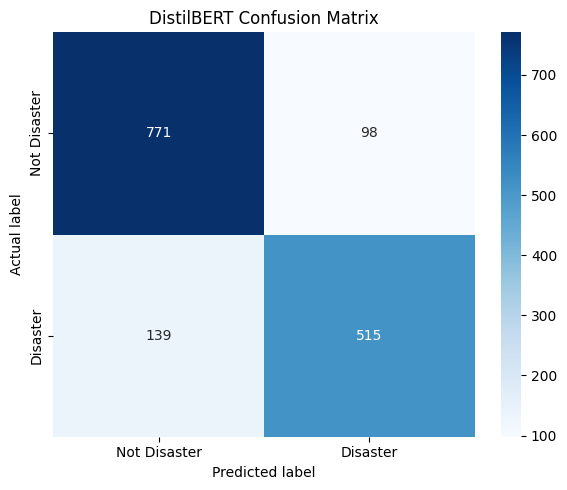

In [18]:
#Step 9 — Examine classification errors

from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Predict on the validation dataset using the trained model
pred_output = trainer.predict(val_dataset)

val_predictions = np.argmax(
    pred_output.predictions, axis=1
)

print(classification_report(
    y_val,
    val_predictions,
    target_names=["Not Disaster (0)", "Disaster (1)"],
    digits=4
))

cm = confusion_matrix(y_val, val_predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Disaster", "Disaster"],
    yticklabels=["Not Disaster", "Disaster"]
)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("DistilBERT Confusion Matrix")
plt.tight_layout()
plt.show()

In [19]:
# Tokenize the Kaggle test tweets
test_texts = test["text"].fillna("").astype(str).tolist()

test_encodings = tokenizer(
    test_texts,
    truncation=True,
    padding="max_length",
    max_length=128
)

test_dataset = Dataset.from_dict(test_encodings)
test_dataset.set_format("torch")

# Predict using the best checkpoint
test_output = trainer.predict(test_dataset)

test_predictions = np.argmax(
    test_output.predictions, axis=1
)

# Create the Kaggle submission
submission = sample_submission[["id"]].copy()
submission["target"] = test_predictions.astype(int)

submission.to_csv(
    "/content/submission_distilbert.csv",
    index=False
)

print(submission.head())
print("\nSubmission shape:", submission.shape)
print("\nPrediction counts:")
print(submission["target"].value_counts())

assert submission.shape == (3263, 2)
assert submission["target"].isin([0, 1]).all()
assert submission["id"].equals(sample_submission["id"])

print("\nSubmission file created and validated.")

   id  target
0   0       1
1   2       1
2   3       1
3   9       1
4  11       1

Submission shape: (3263, 2)

Prediction counts:
target
0    1993
1    1270
Name: count, dtype: int64

Submission file created and validated.


In [20]:
import os

MODEL_DIR = "/content/distilbert_disaster_model"

trainer.save_model(MODEL_DIR)
tokenizer.save_pretrained(MODEL_DIR)

print("Model saved to:", MODEL_DIR)
print("Saved files:")
print(os.listdir(MODEL_DIR))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to: /content/distilbert_disaster_model
Saved files:
['model.safetensors', 'config.json', 'training_args.bin', 'tokenizer.json', 'tokenizer_config.json']


In [21]:
import shutil

shutil.make_archive(
    "/content/distilbert_disaster_model",
    "zip",
    MODEL_DIR
)

print("ZIP created: /content/distilbert_disaster_model.zip")

ZIP created: /content/distilbert_disaster_model.zip
